# Fuzzy Logic Fuel Economy Prediction for a Toyota Tundra

**Course:** AIT 525

**Assignment:** Fuzzy Logic

**By:** Yashu Lanki

## Part 1: Introduction to Fuzzy Logic and Problem Definition

**What is fuzzy logic?** Fuzzy logic handles statements that can be partly true (Zadeh, 1965). Binary logic allows only true or false, but in fuzzy logic a statement can be partly both, and its truth is a degree between 0 and 1. For instance, 98°F can be 0.8 "hot."

**Advantages in AI.** Fuzzy logic is useful in AI because it can handle vague words like people use, such as "a bit heavy" or "fairly steep," and its output changes gradually instead of jumping at a hard cutoff.

**Key components.**
- **Fuzzy sets:** labels for an input, such as light, medium, and heavy cargo (Zadeh, 1965).
- **Membership functions:** turn a number into a degree between 0 and 1. For example, 900 lbs could be 0.6 "medium."
- **If-then rules:** connect input conditions to the output, such as "If cargo is heavy and incline is steep, then MPG is low" (Mamdani & Assilian, 1975).

**Problem statement.** This system predicts a Toyota Tundra's fuel economy (MPG) from its cargo load and the road incline, to help a driver estimate fuel use before a trip. Fuzzy logic suits this problem because there is no exact weight where cargo becomes "heavy" or exact grade where a road becomes "steep." Drivers describe these conditions in vague terms, and MPG drops gradually as both increase rather than jumping at a hard cutoff.

## Part 2: Designing the Fuzzy Logic System

**Fuzzy sets and membership functions.** Each variable uses triangular membership functions [start, peak, end]. Neighboring sets overlap so values change gradually.

| Variable | Range | Set | Start | Peak | End |
|---|---|---|---|---|---|
| Cargo load (input) | 0–1,700 lbs | Light | 0 | 0 | 800 |
| | | Medium | 400 | 850 | 1,300 |
| | | Heavy | 900 | 1,700 | 1,700 |
| Road incline (input) | 0–10% grade | Flat | 0 | 0 | 4 |
| | | Moderate | 2 | 5 | 8 |
| | | Steep | 6 | 10 | 10 |
| Expected MPG (output) | 10–24 MPG | Low | 10 | 10 | 16 |
| | | Medium | 13 | 17 | 21 |
| | | High | 18 | 24 | 24 |

The cargo range matches the Tundra's approximate payload. The MPG range tops out at the Tundra's EPA highway rating of about 24 MPG (U.S. Department of Energy & U.S. Environmental Protection Agency, n.d.).

**Membership functions in code.** The cell below creates the two inputs as `Antecedent` objects and the output as a `Consequent` object, each with a range of values (its universe). Each fuzzy set is a triangle built with `fuzz.trimf` from its [start, peak, end] points (scikit-fuzzy developers, 2024). The next cell plots every membership function.

In [1]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

from skfuzzy import control as ctrl

cargo = ctrl.Antecedent(np.arange(0, 1701, 1), 'cargo')
cargo['light'] = fuzz.trimf(cargo.universe, [0, 0, 800])
cargo['medium'] = fuzz.trimf(cargo.universe, [400, 850, 1300])
cargo['heavy'] = fuzz.trimf(cargo.universe, [900, 1700, 1700])

incline = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'incline')
incline['flat'] = fuzz.trimf(incline.universe, [0, 0, 4])
incline['moderate'] = fuzz.trimf(incline.universe, [2, 5, 8])
incline['steep'] = fuzz.trimf(incline.universe, [6, 10, 10])

mpg = ctrl.Consequent(np.arange(10, 24.1, 0.1), 'mpg')
mpg['low'] = fuzz.trimf(mpg.universe, [10, 10, 16])
mpg['medium'] = fuzz.trimf(mpg.universe, [13, 17, 21])
mpg['high'] = fuzz.trimf(mpg.universe, [18, 24, 24])

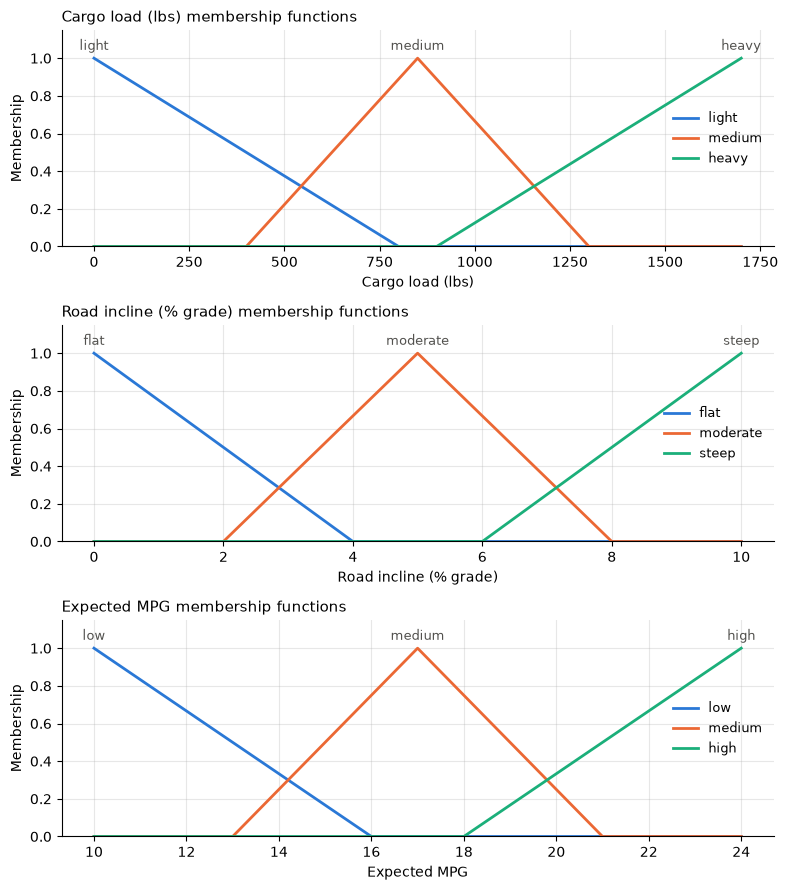

In [2]:
colors = ['#2a78d6', '#eb6834', '#1baf7a']
variables = [
    (cargo, 'Cargo load (lbs)'),
    (incline, 'Road incline (% grade)'),
    (mpg, 'Expected MPG'),
]

fig, axes = plt.subplots(3, 1, figsize=(8, 9))
for ax, (var, xlabel) in zip(axes, variables):
    for color, (label, term) in zip(colors, var.terms.items()):
        ax.plot(var.universe, term.mf, color=color, linewidth=2, label=label)
        peak = var.universe[np.argmax(term.mf)]
        ax.annotate(label, (peak, 1.0), xytext=(0, 6), textcoords='offset points',
                    ha='center', fontsize=9, color='#52514e')
    ax.set_title(f'{xlabel} membership functions', loc='left', fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Membership')
    ax.set_ylim(0, 1.15)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='center right', frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

**Reading the diagrams.** Each line shows how strongly a value belongs to a set, from 0 (not at all) to 1 (fully). Where two triangles overlap, a value belongs partly to both. For example, 600 lbs is about 0.25 "light" and 0.44 "medium." These overlaps let the system move smoothly from one label to the next.

**Fuzzy rules.** The system uses nine rules, one for each combination of inputs, so every possible input fires at least one rule:

| Cargo \ Incline | Flat | Moderate | Steep |
|---|---|---|---|
| **Light** | High | High | Medium |
| **Medium** | High | Medium | Low |
| **Heavy** | Medium | Low | Low |

**Purpose of the rules.**
- **Best case** (light + flat): the engine works less, so it uses less fuel and MPG is high.
- **Worst case** (heavy + steep, heavy + moderate, medium + steep): the engine works harder, so it uses more fuel and MPG is low.
- **Mixed cases** (heavy + flat, light + steep, medium + moderate): one input makes the engine work harder and the other makes it easier, so MPG lands in the middle.
- **Leaning cases** (light + moderate, medium + flat): when one input is in the middle, MPG leans toward the other input.

## Part 3: Implementing the Fuzzy Logic System in Python

**Code structure.** The system is built in four steps:

1. **Variables and membership functions** (Part 2): `cargo` and `incline` are the inputs, and `mpg` is the output.
2. **Rules:** each `ctrl.Rule` links two input sets to one output set, where `&` means AND. The nine rules match the rule table in Part 2.
3. **Control system:** `ctrl.ControlSystem` collects the rules, and `ctrl.ControlSystemSimulation` runs them on specific inputs.
4. **Prediction:** `predict_mpg` passes in a cargo load and an incline and returns the predicted MPG.

**How the system makes a decision.** This is a Mamdani fuzzy system (Mamdani & Assilian, 1975). For a given input, it:

1. **Fuzzifies** each input: finds its degree of membership in every set (for example, 1,600 lbs is 0.875 "heavy").
2. **Applies the rules:** each rule's strength is the *smaller* of its two input degrees, because AND takes the minimum (Zadeh, 1965).
3. **Clips** each output set at its rule's strength, then combines all the clipped shapes.
4. **Defuzzifies:** takes the center of mass (centroid) of the combined shape as the final crisp MPG (Ross, 2010).

In [3]:
rules = [
    ctrl.Rule(cargo['light'] & incline['flat'], mpg['high']),
    ctrl.Rule(cargo['light'] & incline['moderate'], mpg['high']),
    ctrl.Rule(cargo['light'] & incline['steep'], mpg['medium']),
    ctrl.Rule(cargo['medium'] & incline['flat'], mpg['high']),
    ctrl.Rule(cargo['medium'] & incline['moderate'], mpg['medium']),
    ctrl.Rule(cargo['medium'] & incline['steep'], mpg['low']),
    ctrl.Rule(cargo['heavy'] & incline['flat'], mpg['medium']),
    ctrl.Rule(cargo['heavy'] & incline['moderate'], mpg['low']),
    ctrl.Rule(cargo['heavy'] & incline['steep'], mpg['low']),
]

tundra_ctrl = ctrl.ControlSystem(rules)
tundra_sim = ctrl.ControlSystemSimulation(tundra_ctrl)

**Test cases.** Three realistic driving scenarios, from best case to worst case.

In [4]:
def predict_mpg(cargo_lbs, incline_pct):
    tundra_sim.input['cargo'] = cargo_lbs
    tundra_sim.input['incline'] = incline_pct
    tundra_sim.compute()
    return tundra_sim.output['mpg']

test_cases = [
    ('Empty truck on a flat highway', 200, 1),
    ('Half load on a rolling hill', 850, 5),
    ('Near-full load on a steep mountain pass', 1600, 9),
]

for name, load, grade in test_cases:
    print(f'{name}: {load} lbs, {grade}% grade -> {predict_mpg(load, grade):.1f} MPG')

Empty truck on a flat highway: 200 lbs, 1% grade -> 21.9 MPG
Half load on a rolling hill: 850 lbs, 5% grade -> 17.0 MPG
Near-full load on a steep mountain pass: 1600 lbs, 9% grade -> 12.1 MPG


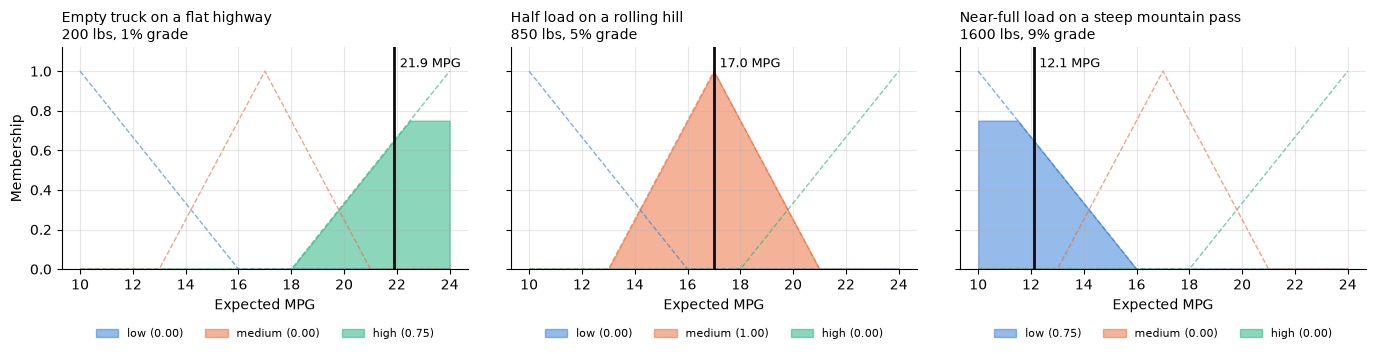

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, load, grade) in zip(axes, test_cases):
    result = predict_mpg(load, grade)
    for color, (label, term) in zip(colors, mpg.terms.items()):
        ax.plot(mpg.universe, term.mf, color=color, linewidth=1, linestyle='--', alpha=0.6)
        strength = term.membership_value[tundra_sim]
        ax.fill_between(mpg.universe, np.fmin(term.mf, strength), color=color, alpha=0.5,
                        label=f'{label} ({strength:.2f})')
    ax.axvline(result, color='#0b0b0b', linewidth=2)
    ax.annotate(f'{result:.1f} MPG', (result, 1.02), xytext=(4, 0), textcoords='offset points',
                ha='left', fontsize=9)
    ax.set_title(f'{name}\n{load} lbs, {grade}% grade', loc='left', fontsize=10)
    ax.set_xlabel('Expected MPG')
    ax.set_ylim(0, 1.12)
    ax.grid(alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False, fontsize=8)
axes[0].set_ylabel('Membership')
plt.tight_layout()
plt.show()

**Test case results.** The shaded areas show how strongly each output set fired, and the black line marks the final MPG.

| Test case | Cargo | Incline | Input memberships | Rule that fired (strength) | Predicted MPG |
|---|---|---|---|---|---|
| Empty truck on a flat highway | 200 lbs | 1% | 0.75 light, 0.75 flat | Light + flat → high (0.75) | **21.9** |
| Half load on a rolling hill | 850 lbs | 5% | 1.0 medium, 1.0 moderate | Medium + moderate → medium (1.0) | **17.0** |
| Near-full load on a steep pass | 1,600 lbs | 9% | 0.875 heavy, 0.75 steep | Heavy + steep → low (0.75) | **12.1** |

- **Test case 1:** a light load on a flat road makes the engine work the least, so MPG is high. The result, 21.9 MPG, is close to the Tundra's EPA combined rating of about 20–22 MPG (U.S. Department of Energy & U.S. Environmental Protection Agency, n.d.). The output stops short of 24 because the centroid sits in the middle of the shaded "high" area, not at its far edge.
- **Test case 2:** 850 lbs and 5% are the exact peaks of "medium" and "moderate," so only one rule fires at full strength and the output is the center of the "medium" MPG set, 17.0.
- **Test case 3:** a heavy load on a steep climb makes the engine work hardest, so MPG drops to 12.1, about 45% below test case 1.

**Output across all inputs.** The heatmap below runs the system on every combination of cargo load (0–1,700 lbs) and incline (0–10%). Lighter colors mean higher MPG, and the three test cases are marked.

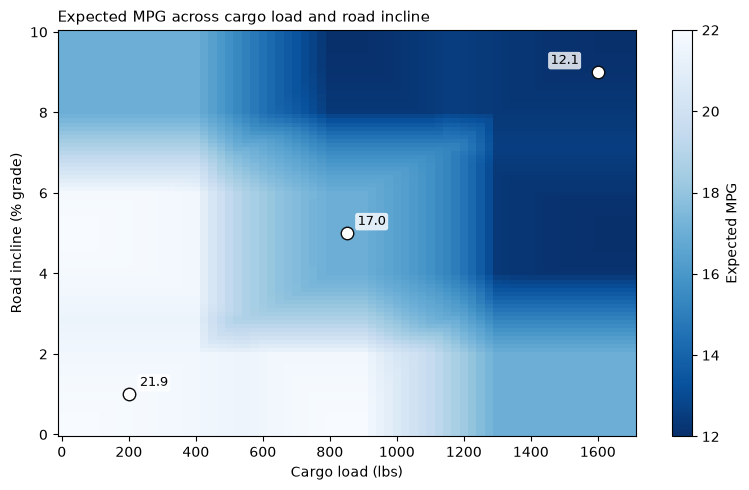

In [6]:
cargo_grid = np.arange(0, 1701, 25)
incline_grid = np.arange(0, 10.1, 0.1)
mpg_grid = np.array([[predict_mpg(c, i) for c in cargo_grid] for i in incline_grid])

fig, ax = plt.subplots(figsize=(8, 5))
mesh = ax.pcolormesh(cargo_grid, incline_grid, mpg_grid, cmap='Blues_r', shading='auto')
fig.colorbar(mesh, ax=ax, label='Expected MPG')
for name, load, grade in test_cases:
    ax.plot(load, grade, 'o', markersize=9, markerfacecolor='white', markeredgecolor='#0b0b0b')
    ax.annotate(f'{predict_mpg(load, grade):.1f}', (load, grade), xytext=(8 if load < 1400 else -34, 6),
                textcoords='offset points', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))
ax.set_title('Expected MPG across cargo load and road incline', loc='left', fontsize=11)
ax.set_xlabel('Cargo load (lbs)')
ax.set_ylabel('Road incline (% grade)')
plt.tight_layout()
plt.show()

**Reading the heatmap.** MPG is highest in the bottom-left (light load, flat road) and lowest in the top-right (heavy load, steep road). Between them, the colors change gradually across the overlap zones (roughly 400–1,300 lbs and 2–8% grade) instead of jumping at a single line. The flat-colored areas are regions where a single rule fires on its own, so the output stays steady until the inputs reach the next overlap.

**Fuzzy vs. crisp output.** The next plot shows how MPG changes as cargo increases, at three road grades. For comparison, the dashed line is a *crisp* (binary) version of the same nine rules: each input belongs to exactly one set (light below 600 lbs, heavy from 1,167 lbs, flat below 3%, steep from 7%), and each rule outputs a fixed MPG.

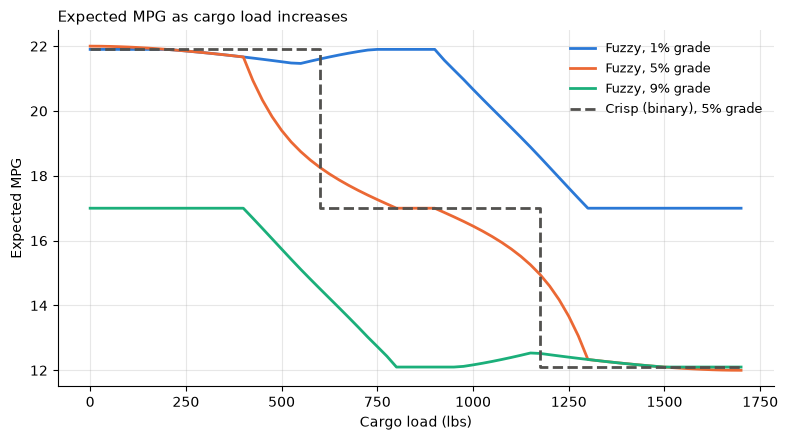

590 lbs, 5% grade -> fuzzy: 18.3 MPG, crisp: 21.9 MPG
610 lbs, 5% grade -> fuzzy: 18.2 MPG, crisp: 17.0 MPG
1160 lbs, 5% grade -> fuzzy: 15.1 MPG, crisp: 17.0 MPG
1175 lbs, 5% grade -> fuzzy: 15.0 MPG, crisp: 12.1 MPG


In [7]:
def crisp_mpg(cargo_lbs, incline_pct):
    load = 'light' if cargo_lbs < 600 else 'medium' if cargo_lbs < 1167 else 'heavy'
    grade = 'flat' if incline_pct < 3 else 'moderate' if incline_pct < 7 else 'steep'
    table = {
        ('light', 'flat'): 'high', ('light', 'moderate'): 'high', ('light', 'steep'): 'medium',
        ('medium', 'flat'): 'high', ('medium', 'moderate'): 'medium', ('medium', 'steep'): 'low',
        ('heavy', 'flat'): 'medium', ('heavy', 'moderate'): 'low', ('heavy', 'steep'): 'low',
    }
    return {'high': 21.9, 'medium': 17.0, 'low': 12.1}[table[(load, grade)]]

fig, ax = plt.subplots(figsize=(8, 4.5))
for color, grade in zip(colors, [1, 5, 9]):
    ax.plot(cargo_grid, [predict_mpg(c, grade) for c in cargo_grid], color=color, linewidth=2,
            label=f'Fuzzy, {grade}% grade')
ax.step(cargo_grid, [crisp_mpg(c, 5) for c in cargo_grid], where='post', color='#52514e',
        linewidth=2, linestyle='--', label='Crisp (binary), 5% grade')

ax.set_title('Expected MPG as cargo load increases', loc='left', fontsize=11)
ax.set_xlabel('Cargo load (lbs)')
ax.set_ylabel('Expected MPG')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

for load in [590, 610, 1160, 1175]:
    print(f'{load} lbs, 5% grade -> fuzzy: {predict_mpg(load, 5):.1f} MPG, crisp: {crisp_mpg(load, 5):.1f} MPG')

**Reading the comparison.** At a 5% grade, the fuzzy line (orange) falls smoothly as cargo increases. The crisp version stays flat and then suddenly drops at each cutoff:

| Cargo (5% grade) | Fuzzy MPG | Crisp MPG |
|---|---|---|
| 590 lbs | 18.3 | 21.9 |
| 610 lbs | 18.2 | 17.0 |
| 1,160 lbs | 15.1 | 17.0 |
| 1,175 lbs | 15.0 | 12.1 |

Adding just 20 lbs, about the weight of a bag of groceries, drops the crisp prediction by about 5 MPG, while the fuzzy prediction changes by 0.1 MPG. The fuzzy result matches how a real truck behaves: fuel use rises gradually with weight. The small dip in the 1% line near 550 lbs happens where cargo is only partly "light" and partly "medium," so the "high" set fires more weakly and its centroid shifts slightly left.

## Fuzzy Logic vs. Traditional Logic

**Traditional logic.** Propositional logic treats every statement as fully true or fully false, and first-order logic adds predicates and variables, such as *Heavy(x)* or *Steep(road)*, but each predicate is still only true or false (Klir & Yuan, 1995). To use either one for this problem, every word needs a hard cutoff, such as "Heavy(cargo) is true if cargo ≥ 1,167 lbs."

**Where traditional logic struggles in this system.**
- **Hard cutoffs give unrealistic jumps.** The crisp version predicts 17.0 MPG at 1,160 lbs but 12.1 MPG at 1,175 lbs. Fifteen extra pounds cannot cut fuel economy by almost 5 MPG.
- **Values in between are forced into one label.** At 600 lbs, a person would say the load is "light to medium." Binary logic must pick one; fuzzy logic says it is 0.25 light and 0.44 medium and uses both rules.
- **Only one rule decides.** In crisp logic, exactly one rule fires. In fuzzy logic, several rules can fire partly and their results are blended, which is closer to how an experienced driver weighs both the load and the hill at once.

**Why fuzzy logic fits human reasoning and natural language.** People describe driving with vague words: "a fairly heavy load," "a bit of a hill," "pretty good mileage." Fuzzy sets give each of those words a precise meaning as a membership curve, so the rules can be written the way a driver would say them and still be calculated exactly (Zadeh, 1965). This makes fuzzy logic a more flexible and realistic model for AI problems built on human judgment, such as control systems, recommendations, and natural-language commands.

## Conclusion

This project built a Mamdani fuzzy logic system that predicts a Toyota Tundra's fuel economy from cargo load and road incline. Using nine rules and triangular membership functions, the system predicted 21.9 MPG for an empty truck on a flat highway, 17.0 MPG for a half load on a rolling hill, and 12.1 MPG for a near-full load on a steep pass. Compared with a crisp version of the same rules, the fuzzy system changes gradually instead of jumping at cutoffs, which shows why fuzzy logic suits problems with vague, human-described inputs. A next step would be tuning the membership functions with real fuel-log data from Tundra drivers.

## References

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, *9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Klir, G. J., & Yuan, B. (1995). *Fuzzy sets and fuzzy logic: Theory and applications*. Prentice Hall.

Mamdani, E. H., & Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. *International Journal of Man-Machine Studies*, *7*(1), 1–13. https://doi.org/10.1016/S0020-7373(75)80002-2

Ross, T. J. (2010). *Fuzzy logic with engineering applications* (3rd ed.). Wiley.

scikit-fuzzy developers. (2024). *scikit-fuzzy* (Version 0.5.0) [Computer software]. https://github.com/scikit-fuzzy/scikit-fuzzy

U.S. Department of Energy & U.S. Environmental Protection Agency. (n.d.). *Toyota Tundra* [Fuel economy data]. Retrieved October 13, 2026, from https://www.fueleconomy.gov

Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, *8*(3), 338–353. https://doi.org/10.1016/S0019-9958(65)90241-X